## CS 329E - Data Science
#### Fall 2026 - Group 8
Name: Eduardo Borges Issa

EID: eb34276

Name: Cheve Garcia

EID: gcg837

Dataset: UCI Adult Dataset (Census Income dataset), extracted from the 1994 US Census Bureau database. It contains demographic, financial, and employment records for approximately 32,561 instances. (https://archive.ics.uci.edu/dataset/2/adult)

#### Problem Statement & Research Question
The research question will investigate what demographic and employment features best predict annual incomes exceeding $50,000, and how effectively class imbalance resampling can mitigate minority class misclassification. To satisfy the requirement for an uncovered technique, the project will be done with SMOTE (Synthetic Minority Over-sampling Technique), which will generate synthetic minority instances by interpolating feature-space nearest neighbors via Euclidean distance to avoid the overfitting risks of naive random duplication. 


## 1. Setup and Imports

In [2]:
# If needed, install the imbalanced-learn package first:
# !pip install imbalanced-learn

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline  # pipeline that allows a resampling step
from sklearn.compose import ColumnTransformer
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    TunedThresholdClassifierCV,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
%matplotlib inline

## 2. Loading the Data

In [3]:
# load the training dataset from the 'adult' subfolder
columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    "income",
]

# load only adult.data
df = pd.read_csv("adult/adult.data", header=None, names=columns, skipinitialspace=True, na_values="?")
print(f"Raw dataset shape: {df.shape}")

n_dup = df.duplicated().sum()
print(f"Exact duplicate rows: {n_dup}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing duplicates: {df.shape}")
df.head()

Raw dataset shape: (32561, 15)
Exact duplicate rows: 24
Shape after removing duplicates: (32537, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 3. Data Cleaning and Class Imbalance

In [4]:
# data cleaning & missing values
# whitespace -> nan
df = df.replace(r"^\s*\?\s*$", np.nan, regex=True)

str_cols = df.select_dtypes(exclude="number").columns
df[str_cols] = df[str_cols].apply(lambda x: x.str.strip())

print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# drop rows with missing values
df_clean = df.dropna().copy()
print(f"\nOriginal shape: {df.shape}")
print(f"Shape after dropping missing rows: {df_clean.shape}")

Missing values per column:
workclass         1836
occupation        1843
native_country     582
dtype: int64

Original shape: (32537, 15)
Shape after dropping missing rows: (30139, 15)


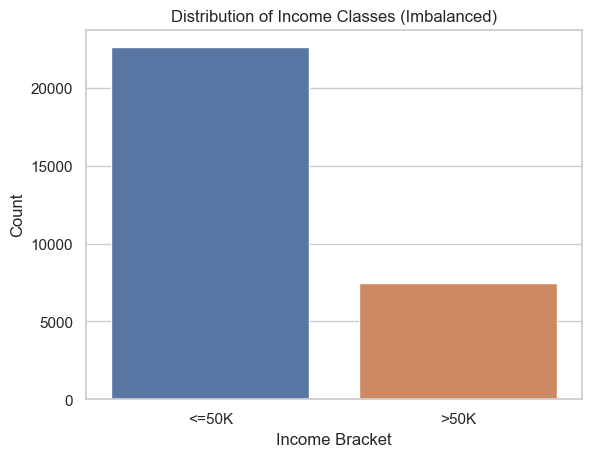

In [5]:
# distribution visualization
sns.countplot(x="income", hue="income", data=df_clean)
plt.title("Distribution of Income Classes (Imbalanced)")
plt.xlabel("Income Bracket")
plt.ylabel("Count")
plt.show()

The above graphic shows the need for SMOTE: with an imbalanced dataset like this (where the majority of the datapoints are from those who make less than $50k a year), SMOTE can help the machine learning algorithm by generating new data to fill the gaps. These 'fake' data points are created before the model is trained, so that the model can properly learn correctly despite the imbalanced data.

## 4. Feature Preparation

Two columns are removed before modeling:

* **`education`** is a text version of **`education_num`** (each education level maps to exactly one number), so keeping both would duplicate the same information. We keep the numeric version because it preserves the natural ordering of education levels.
* **`fnlwgt`** ("final weight") is a census sampling weight that estimates how many people in the population a row represents. It describes the survey design, not the person, so it should not be used as a predictor.

The target `income` is converted to a binary label: **1 = ">50K"** (minority, positive class) and **0 = "<=50K"**.

We then create a **stratified 80/20 train/test split**, so both sets keep the original class proportions. The test set is set aside and only used for the final evaluation of every model.

In [6]:
df_model = df_clean.drop(columns=["education", "fnlwgt"]).copy()
df_model["income"] = (df_model["income"] == ">50K").astype(int)

X = df_model.drop(columns="income")
y = df_model["income"]

num_cols = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
cat_cols = ["workclass", "marital_status", "occupation", "relationship", "race", "sex", "native_country"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Training set: {X_train.shape},  Test set: {X_test.shape}")
print("\nClass proportions (train):")
print(y_train.value_counts(normalize=True).rename({0: "<=50K", 1: ">50K"}).round(3))
print("\nClass proportions (test):")
print(y_test.value_counts(normalize=True).rename({0: "<=50K", 1: ">50K"}).round(3))
print(f"\nImbalance ratio (majority : minority) = {(y_train == 0).sum() / (y_train == 1).sum():.2f} : 1")

Training set: (24111, 12),  Test set: (6028, 12)

Class proportions (train):
income
<=50K    0.751
>50K     0.249
Name: proportion, dtype: float64

Class proportions (test):
income
<=50K    0.751
>50K     0.249
Name: proportion, dtype: float64

Imbalance ratio (majority : minority) = 3.02 : 1


#### Exploratory look at the main features
Before modeling, we look at how a few features relate to income. This gives us a first, informal answer to the research question that we can later compare with the model results.

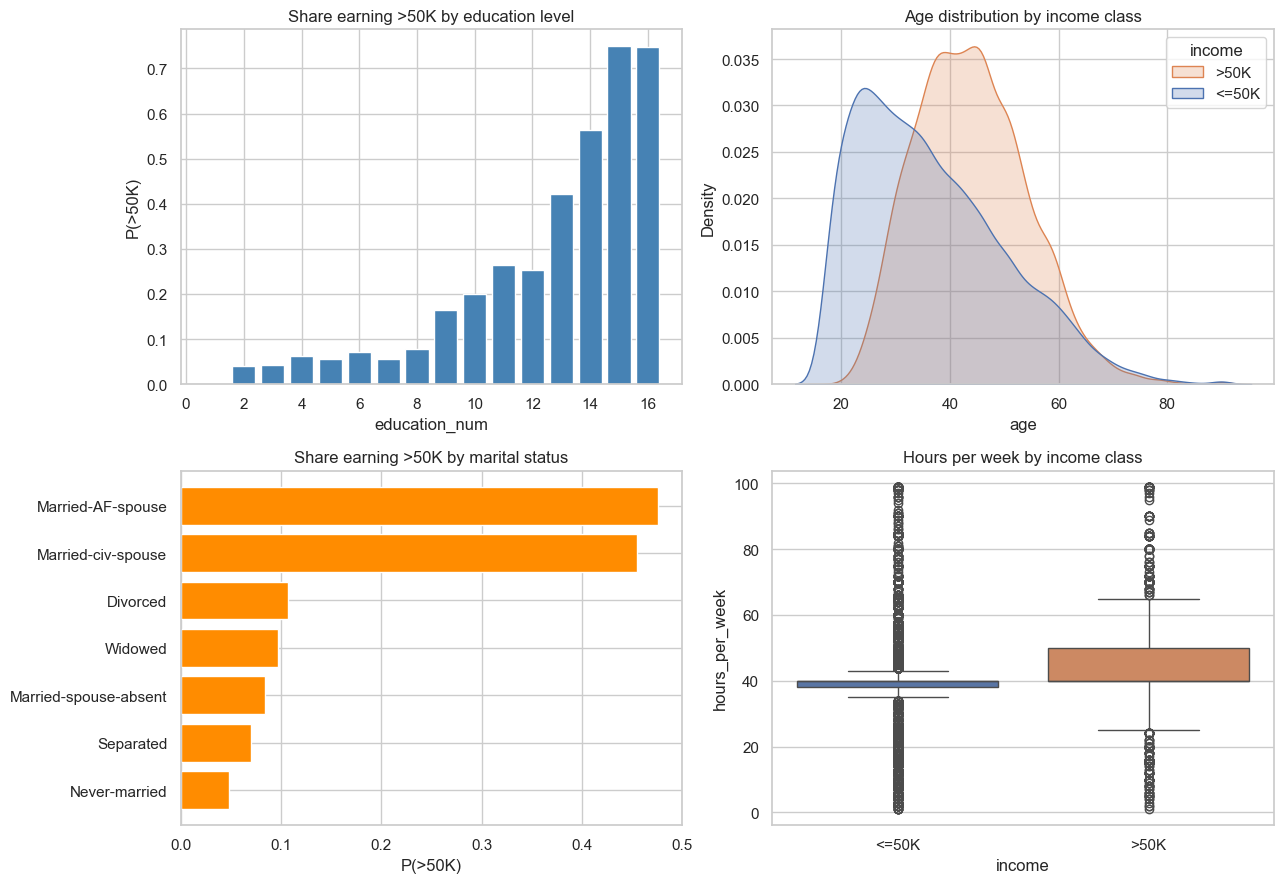

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# share of >50K by education level
edu_rate = df_model.groupby("education_num")["income"].mean()
axes[0, 0].bar(edu_rate.index, edu_rate.values, color="steelblue")
axes[0, 0].set(title="Share earning >50K by education level", xlabel="education_num", ylabel="P(>50K)")

# age distribution by class
sns.kdeplot(data=df_model, x="age", hue="income", common_norm=False, fill=True, ax=axes[0, 1])
axes[0, 1].set(title="Age distribution by income class")
axes[0, 1].legend(title="income", labels=[">50K", "<=50K"])

# share of >50K by marital status
mar_rate = df_model.groupby("marital_status")["income"].mean().sort_values()
axes[1, 0].barh(mar_rate.index, mar_rate.values, color="darkorange")
axes[1, 0].set(title="Share earning >50K by marital status", xlabel="P(>50K)")

# hours per week by class
sns.boxplot(data=df_model, x="income", y="hours_per_week", hue="income", legend=False, ax=axes[1, 1])
axes[1, 1].set(title="Hours per week by income class", xticks=[0, 1], xticklabels=["<=50K", ">50K"])

plt.tight_layout()
plt.show()

## 5. Preprocessing: Scaling and Encoding

All preprocessing is done inside a scikit-learn `ColumnTransformer`:

* **Numeric features** are standardized with `StandardScaler` (each feature gets mean 0 and standard deviation 1).
* **Categorical features** are one-hot encoded with `OneHotEncoder`. `handle_unknown="ignore"` prevents errors if a rare category (for example, a rare country) appears only in the test set.

**Why scaling matters for this project:**
1. **For SMOTE:** SMOTE finds each minority point's nearest neighbors using **Euclidean distance**. Without scaling, `capital_gain` (range 0 to 99,999) would dominate the distance completely, and `age` or `hours_per_week` would barely matter. Scaling puts all numeric features on a comparable scale, so the "neighbors" are actually similar people.
2. **For Logistic Regression:** the regularization penalty treats all coefficients equally, so features should be on the same scale. Scaling also helps the solver converge, and it makes coefficient sizes comparable when we interpret feature importance.
3. **For Random Forest:** trees split on thresholds, so scaling does not change the model, but it does not hurt either, and it keeps one shared preprocessing step for every model.

The scaler and encoder are placed **inside the pipeline**, so they are fit only on training data (or on the training folds during cross-validation). This prevents information from the test set from leaking into training.

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)

# quick check of the transformed feature space
X_train_prep = preprocessor.fit_transform(X_train)
print(f"Features after encoding: {X_train_prep.shape[1]}  (from {X_train.shape[1]} original columns)")
print("\nMean / std of scaled numeric features (train):")
print(pd.DataFrame(X_train_prep[:, : len(num_cols)], columns=num_cols).agg(["mean", "std"]).round(3))

Features after encoding: 87  (from 12 original columns)

Mean / std of scaled numeric features (train):
      age  education_num  capital_gain  capital_loss  hours_per_week
mean -0.0            0.0          -0.0          -0.0             0.0
std   1.0            1.0           1.0           1.0             1.0


## 6. SMOTE in Detail

**SMOTE (Synthetic Minority Over-sampling Technique)** was introduced by Chawla et al. (2002). It balances a dataset by **creating new, synthetic minority-class examples** instead of copying existing ones.

#### The problem it solves
When one class is rare (here, people earning >50K are only about 25% of the data), a classifier can reach high accuracy by mostly predicting the majority class. It learns little about the minority class, which is often the class we care about. Two simple fixes have drawbacks:
* **Random undersampling** (deleting majority rows) throws away real information.
* **Random oversampling** (duplicating minority rows) gives the model the exact same points many times, so it tends to memorize them and overfit.

#### How the algorithm works
For each synthetic point SMOTE needs to create:
1. Pick a minority-class sample $x_i$.
2. Find its $k$ nearest neighbors **among the minority class** (default $k = 5$), using Euclidean distance.
3. Randomly choose one of those neighbors, $x_{zi}$.
4. Create a new point on the line segment between them:
$$x_{new} = x_i + \lambda \cdot (x_{zi} - x_i), \qquad \lambda \sim \text{Uniform}(0, 1)$$
5. Repeat until the minority class reaches the desired size (by default, the same size as the majority class).

Because each new point lies *between* two real minority points, SMOTE fills in the minority region of the feature space instead of stacking duplicates. This pushes the decision boundary outward and helps the model generalize to minority cases it has not seen.

#### Important rules and limitations
* **Apply SMOTE only to the training data.** The test set must reflect the real-world class distribution. If synthetic points were created before the split, information from test rows would leak into training. We use `imblearn.pipeline.Pipeline`, which runs SMOTE only during `fit` and skips it during `predict`. During cross-validation, SMOTE is applied separately inside each training fold.
* **Scaling is required first**, because neighbors are found with Euclidean distance (see Section 5).
* **Noise and overlap:** if a minority point is an outlier inside the majority region, SMOTE creates more points in that wrong region, which can increase false positives.
* **Categorical features:** after one-hot encoding, interpolation can produce values between 0 and 1 (for example, "0.4 Married, 0.6 Divorced"). Models still work with these values, but they are not real categories. The variant **SMOTE-NC** handles categorical features directly and is a possible extension.
* **Trade-off:** SMOTE usually **raises recall** on the minority class but **lowers precision**, because the model becomes more willing to predict the minority class.

#### SMOTE from scratch
To show the mechanism clearly, the next cell implements the core of SMOTE in a few lines and compares it with the `imblearn` version on a small 2-D toy dataset.

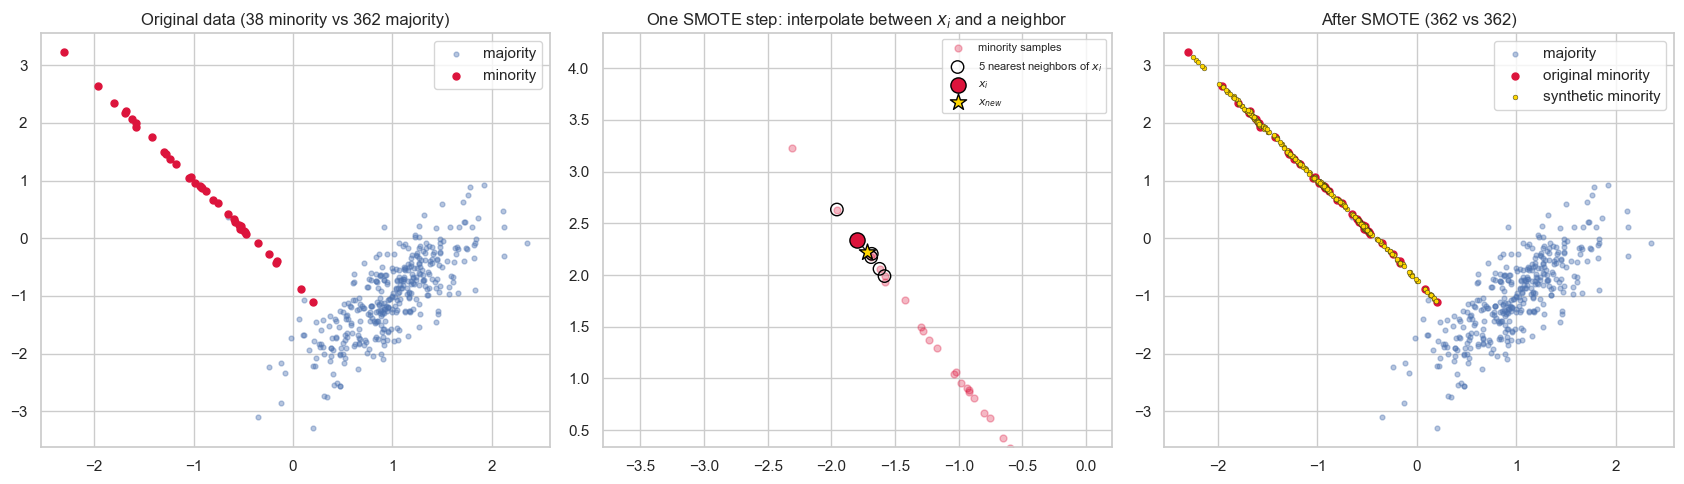

From scratch: 324 synthetic points, mean = [-0.9   0.83]
imblearn    : 324 synthetic points, mean = [-0.96  0.93]


In [9]:
def smote_from_scratch(X_min, n_new, k=5, random_state=0):
    """Generate n_new synthetic samples from minority samples X_min (basic SMOTE)."""
    rng = np.random.default_rng(random_state)
    # k+1 neighbors because each point is its own nearest neighbor
    nn = NearestNeighbors(n_neighbors=k + 1).fit(X_min)
    neighbors = nn.kneighbors(X_min, return_distance=False)[:, 1:]

    base_idx = rng.integers(0, len(X_min), size=n_new)              # step 1: pick x_i
    neigh_idx = neighbors[base_idx, rng.integers(0, k, size=n_new)]  # steps 2-3: pick a neighbor x_zi
    lam = rng.random((n_new, 1))                                     # step 4: lambda ~ U(0, 1)
    return X_min[base_idx] + lam * (X_min[neigh_idx] - X_min[base_idx]), base_idx, neigh_idx


# toy imbalanced 2-D dataset (90% / 10%)
X_toy, y_toy = make_classification(
    n_samples=400, n_features=2, n_redundant=0, n_clusters_per_class=1,
    weights=[0.9], class_sep=1.0, random_state=7,
)
X_min = X_toy[y_toy == 1]
n_new = (y_toy == 0).sum() - (y_toy == 1).sum()

X_syn, base_idx, neigh_idx = smote_from_scratch(X_min, n_new, k=5)
X_res_lib, y_res_lib = SMOTE(random_state=0).fit_resample(X_toy, y_toy)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# panel 1: original data
axes[0].scatter(*X_toy[y_toy == 0].T, s=12, alpha=0.4, label="majority")
axes[0].scatter(*X_min.T, s=25, color="crimson", label="minority")
axes[0].set_title(f"Original data ({(y_toy == 1).sum()} minority vs {(y_toy == 0).sum()} majority)")
axes[0].legend()

# panel 2: how a single synthetic point is created
i = 0
xi, xz = X_min[base_idx[i]], X_min[neigh_idx[i]]
nn5 = NearestNeighbors(n_neighbors=6).fit(X_min).kneighbors([xi], return_distance=False)[0, 1:]
axes[1].scatter(*X_min.T, s=25, color="crimson", alpha=0.3, label="minority samples")
axes[1].scatter(*X_min[nn5].T, s=80, facecolors="none", edgecolors="black", label="5 nearest neighbors of $x_i$")
axes[1].plot([xi[0], xz[0]], [xi[1], xz[1]], "k--", lw=1)
axes[1].scatter(*xi, s=120, color="crimson", edgecolors="black", label="$x_i$", zorder=3)
axes[1].scatter(*X_syn[i], s=150, marker="*", color="gold", edgecolors="black", label="$x_{new}$", zorder=3)
axes[1].set_title("One SMOTE step: interpolate between $x_i$ and a neighbor")
axes[1].legend(fontsize=8)
pad = 1.0
axes[1].set_xlim(xi[0] - pad * 2, xi[0] + pad * 2)
axes[1].set_ylim(xi[1] - pad * 2, xi[1] + pad * 2)

# panel 3: data after SMOTE (imblearn)
syn_lib = X_res_lib[len(X_toy):]  # imblearn appends the synthetic samples at the end
axes[2].scatter(*X_toy[y_toy == 0].T, s=12, alpha=0.4, label="majority")
axes[2].scatter(*X_min.T, s=25, color="crimson", label="original minority")
axes[2].scatter(*syn_lib.T, s=12, color="gold", edgecolors="k", linewidths=0.3, label="synthetic minority")
axes[2].set_title(f"After SMOTE ({(y_res_lib == 1).sum()} vs {(y_res_lib == 0).sum()})")
axes[2].legend()

plt.tight_layout()
plt.show()

# sanity check: our version and imblearn produce the same number of points in the same region
print(f"From scratch: {len(X_syn)} synthetic points, mean = {X_syn.mean(axis=0).round(2)}")
print(f"imblearn    : {len(syn_lib)} synthetic points, mean = {syn_lib.mean(axis=0).round(2)}")

The left plot shows the imbalance. The middle plot zooms in on one SMOTE step: the new point (star) lies on the dashed line between a minority sample $x_i$ and one of its 5 nearest minority neighbors. The right plot shows the result: the minority region is filled with new, distinct points instead of duplicates, and the two classes are now the same size.

#### SMOTE on the Adult training data
Below we apply SMOTE to the preprocessed training set to see how the class counts change. (In the actual models, this happens automatically inside the pipeline.)

           Before SMOTE  After SMOTE
<=50K (0)         18106        18106
>50K (1)           6005        18106

Synthetic >50K rows created: 12101


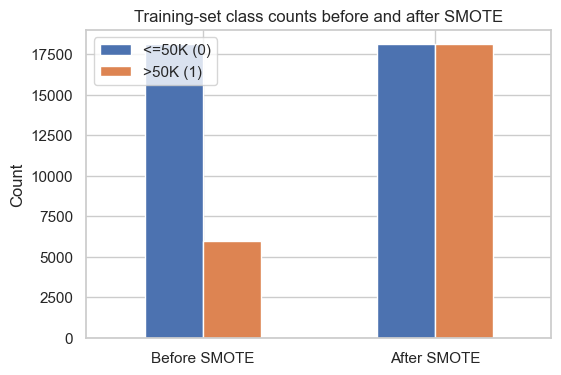

In [10]:
X_train_sm, y_train_sm = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_prep, y_train)

counts = pd.DataFrame({
    "Before SMOTE": y_train.value_counts().sort_index().values,
    "After SMOTE": pd.Series(y_train_sm).value_counts().sort_index().values,
}, index=["<=50K (0)", ">50K (1)"])
print(counts)
print(f"\nSynthetic >50K rows created: {counts.loc['>50K (1)', 'After SMOTE'] - counts.loc['>50K (1)', 'Before SMOTE']}")

counts.T.plot(kind="bar", figsize=(6, 4), rot=0, title="Training-set class counts before and after SMOTE")
plt.ylabel("Count")
plt.show()

## 7. Models and Experimental Design

Following the professor's feedback, we compare **Logistic Regression** and **Random Forest**, each with several ways of handling the class imbalance:

| # | Model | Imbalance handling | Idea |
|---|---|---|---|
| 1 | Logistic Regression | none | baseline |
| 2 | Logistic Regression | class weights | errors on the minority class cost more during training |
| 3 | Logistic Regression | threshold tuning | keep the model, but move the decision threshold from 0.5 to the value that maximizes F1 |
| 4 | Logistic Regression | **SMOTE** | train on a balanced, partly synthetic training set |
| 5 | Random Forest | none | baseline |
| 6 | Random Forest | threshold tuning | as in #3 |
| 7 | Random Forest | **SMOTE** | as in #4 |

**Logistic Regression** models the log-odds of earning >50K as a linear combination of the features and outputs a probability. It is simple and its coefficients are easy to interpret.

**Random Forest** trains many decision trees on bootstrap samples, with a random subset of features at each split, and averages their votes. It can capture non-linear effects and interactions (for example, education mattering more for married people) that a linear model cannot.

**Threshold tuning** uses `TunedThresholdClassifierCV`: it runs 5-fold cross-validation **on the training set only** and picks the probability cut-off that gives the best F1. The test set is never used to choose the threshold.

#### Evaluation metrics
Because only about 25% of people earn >50K, a model that always predicts "<=50K" would already be about 75% accurate. Accuracy alone is therefore misleading. We focus on the **>50K (positive) class**:
* **Precision**: of the people predicted >50K, how many really earn >50K?
* **Recall**: of the people who really earn >50K, how many did the model find?
* **F1 score**: the harmonic mean of precision and recall. **This is our main metric for selecting the best model.**
* **ROC-AUC** and **PR-AUC (average precision)**: threshold-independent measures of how well the model ranks high earners above low earners. PR-AUC is more informative than ROC-AUC under imbalance.
* **Balanced accuracy**: the average of recall on each class.

In [11]:
def make_lr(**kw):
    return LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, **kw)


def make_rf(**kw):
    params = dict(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
    params.update(kw)
    return RandomForestClassifier(**params)


def plain_pipe(clf):
    return Pipeline([("prep", preprocessor), ("clf", clf)])


def smote_pipe(clf):
    # imblearn pipeline: SMOTE runs only when fitting (training data), never when predicting
    return ImbPipeline([("prep", preprocessor), ("smote", SMOTE(random_state=RANDOM_STATE)), ("clf", clf)])


def threshold_tuned(pipe):
    return TunedThresholdClassifierCV(
        pipe, scoring="f1", cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    )


models = {
    "LR (baseline)": plain_pipe(make_lr()),
    "LR + class weights": plain_pipe(make_lr(class_weight="balanced")),
    "LR + threshold tuning": threshold_tuned(plain_pipe(make_lr())),
    "LR + SMOTE": smote_pipe(make_lr()),
    "RF (baseline)": plain_pipe(make_rf()),
    "RF + threshold tuning": threshold_tuned(plain_pipe(make_rf())),
    "RF + SMOTE": smote_pipe(make_rf()),
}


def evaluate(model, X_te, y_te):
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    return {
        "Accuracy": accuracy_score(y_te, y_pred),
        "Balanced Acc.": balanced_accuracy_score(y_te, y_pred),
        "Precision (>50K)": precision_score(y_te, y_pred),
        "Recall (>50K)": recall_score(y_te, y_pred),
        "F1 (>50K)": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, y_prob),
        "PR-AUC": average_precision_score(y_te, y_prob),
    }, y_pred, y_prob


results, preds, probs = {}, {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    results[name], preds[name], probs[name] = evaluate(model, X_test, y_test)
    extra = f" (chosen threshold = {model.best_threshold_:.3f})" if hasattr(model, "best_threshold_") else ""
    print(f"Trained: {name}{extra}")

Trained: LR (baseline)
Trained: LR + class weights
Trained: LR + threshold tuning (chosen threshold = 0.343)
Trained: LR + SMOTE
Trained: RF (baseline)
Trained: RF + threshold tuning (chosen threshold = 0.323)
Trained: RF + SMOTE


### 7.1 Test-set results

In [12]:
results_df = pd.DataFrame(results).T
results_df.style.format("{:.3f}").highlight_max(axis=0, color="lightgreen")

,Accuracy,Balanced Acc.,Precision (>50K),Recall (>50K),F1 (>50K),ROC-AUC,PR-AUC
LR (baseline),0.847,0.766,0.734,0.606,0.664,0.900,0.766
LR + class weights,0.804,0.811,0.575,0.825,0.678,0.900,0.764
LR + threshold tuning,0.832,0.801,0.642,0.740,0.687,0.900,0.766
LR + SMOTE,0.805,0.812,0.575,0.826,0.678,0.899,0.763
RF (baseline),0.848,0.776,0.723,0.634,0.675,0.898,0.763
RF + threshold tuning,0.835,0.812,0.642,0.766,0.698,0.898,0.763
RF + SMOTE,0.840,0.787,0.677,0.682,0.680,0.892,0.735


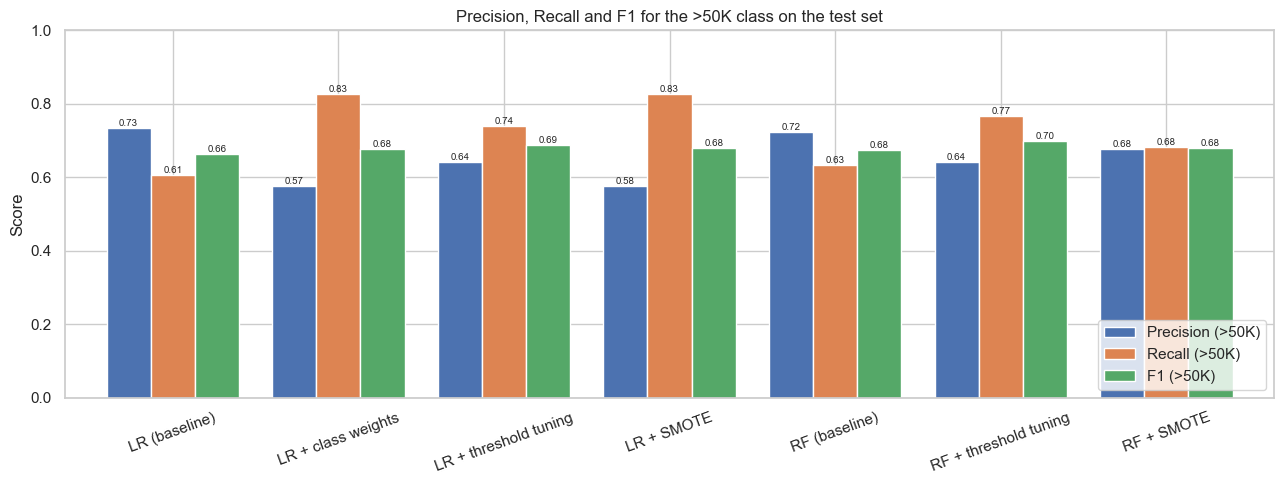

In [13]:
metrics_to_plot = ["Precision (>50K)", "Recall (>50K)", "F1 (>50K)"]
ax = results_df[metrics_to_plot].plot(kind="bar", figsize=(13, 5), rot=20, width=0.8)
ax.set_title("Precision, Recall and F1 for the >50K class on the test set")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=7)
plt.tight_layout()
plt.show()

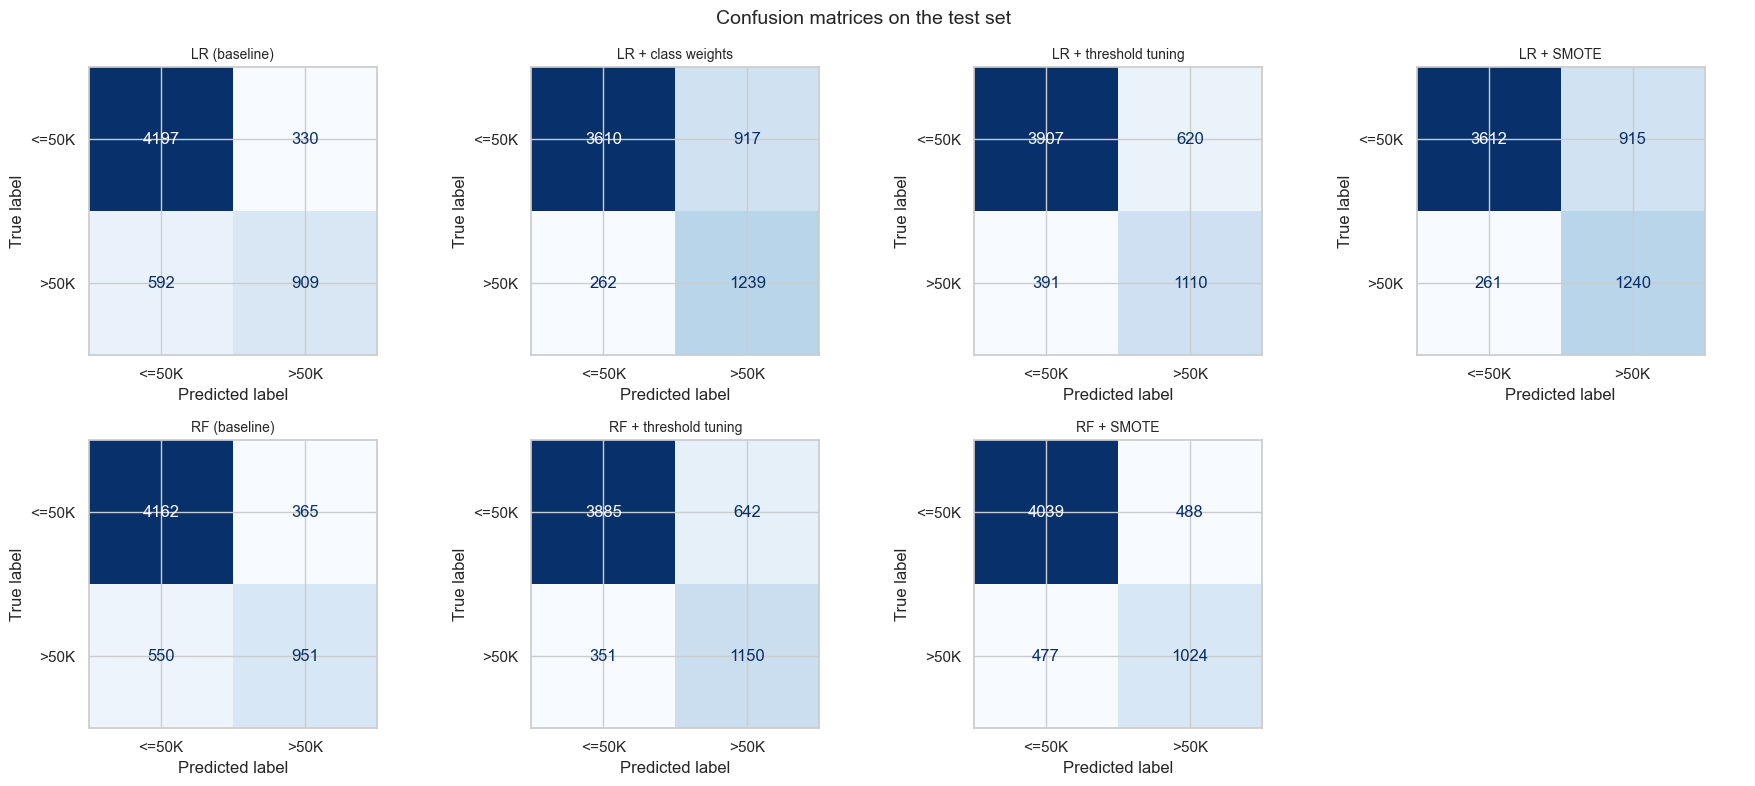

Detailed report for LR (baseline):
              precision    recall  f1-score   support

       <=50K      0.876     0.927     0.901      4527
        >50K      0.734     0.606     0.664      1501

    accuracy                          0.847      6028
   macro avg      0.805     0.766     0.782      6028
weighted avg      0.841     0.847     0.842      6028

Detailed report for LR + SMOTE:
              precision    recall  f1-score   support

       <=50K      0.933     0.798     0.860      4527
        >50K      0.575     0.826     0.678      1501

    accuracy                          0.805      6028
   macro avg      0.754     0.812     0.769      6028
weighted avg      0.844     0.805     0.815      6028



In [14]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, name in zip(axes.ravel(), models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds[name], display_labels=["<=50K", ">50K"], cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name, fontsize=10)
axes.ravel()[-1].axis("off")
plt.suptitle("Confusion matrices on the test set", fontsize=14)
plt.tight_layout()
plt.show()

print("Detailed report for LR (baseline):")
print(classification_report(y_test, preds["LR (baseline)"], target_names=["<=50K", ">50K"], digits=3))
print("Detailed report for LR + SMOTE:")
print(classification_report(y_test, preds["LR + SMOTE"], target_names=["<=50K", ">50K"], digits=3))

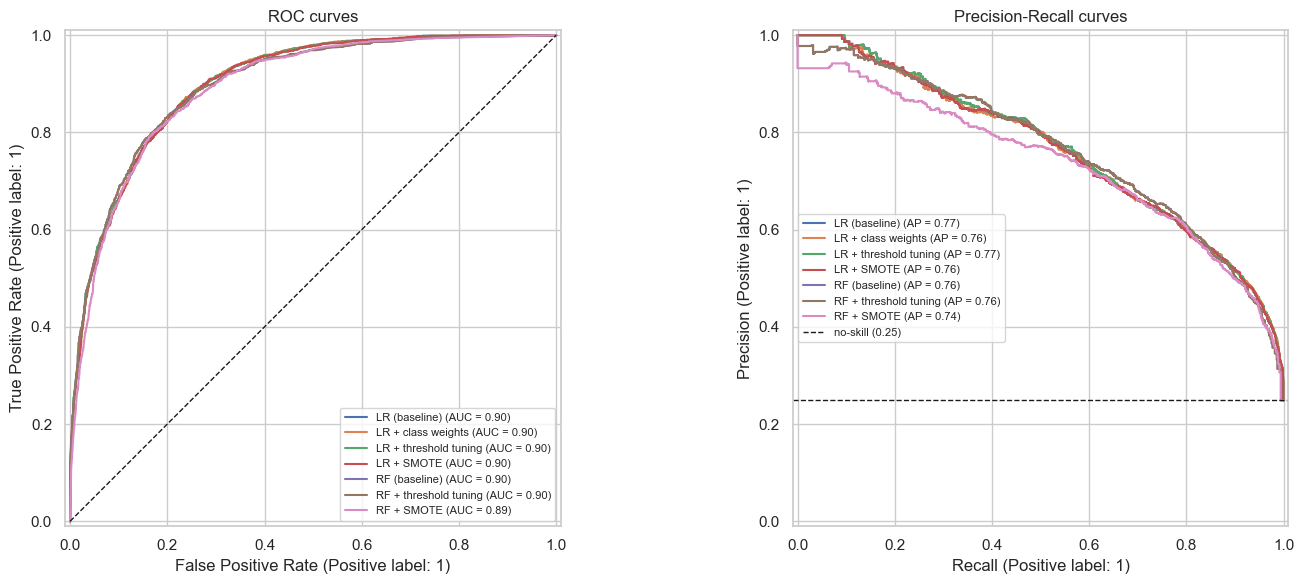

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name in models:
    RocCurveDisplay.from_predictions(y_test, probs[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probs[name], name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("ROC curves")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"no-skill ({y_test.mean():.2f})")
axes[1].set_title("Precision-Recall curves")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 7.2 Is the difference real? 5-fold cross-validation
A single test split can be lucky or unlucky. To check that the differences between models are stable, we run **stratified 5-fold cross-validation on the training set** for the main configurations and report the mean and standard deviation of each metric. SMOTE is applied inside each training fold only, so the validation fold always keeps the real class distribution.

*(Running this cell can take a few minutes because of the Random Forest models.)*

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_models = ["LR (baseline)", "LR + class weights", "LR + SMOTE", "RF (baseline)", "RF + SMOTE"]
scoring = {"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

cv_rows = {}
for name in cv_models:
    scores = cross_validate(models[name], X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows[name] = {
        f"{m} (mean ± std)": f"{scores['test_' + m].mean():.3f} ± {scores['test_' + m].std():.3f}"
        for m in scoring
    }
    print(f"Done: {name}")

cv_df = pd.DataFrame(cv_rows).T
cv_df

Done: LR (baseline)
Done: LR + class weights
Done: LR + SMOTE
Done: RF (baseline)
Done: RF + SMOTE


,precision (mean ± std),recall (mean ± std),f1 (mean ± std),roc_auc (mean ± std)
LR (baseline),0.733 ± 0.009,0.609 ± 0.016,0.666 ± 0.010,0.905 ± 0.002
LR + class weights,0.582 ± 0.006,0.845 ± 0.010,0.689 ± 0.005,0.905 ± 0.002
LR + SMOTE,0.582 ± 0.006,0.843 ± 0.012,0.688 ± 0.006,0.904 ± 0.002
RF (baseline),0.713 ± 0.007,0.625 ± 0.013,0.666 ± 0.008,0.890 ± 0.005
RF + SMOTE,0.666 ± 0.011,0.673 ± 0.017,0.669 ± 0.014,0.886 ± 0.005


### 7.3 Interpretation of the model comparison

*Note: the discussion below describes the pattern the results show. Check the exact values against the tables and plots above after running the notebook, since they depend on the run.*

**Effect of SMOTE.** Compared with the baseline models, SMOTE strongly increases **recall** on the >50K class: the model now identifies a much larger share of the real high earners (see the bottom-right cell of each confusion matrix). The cost is lower **precision**, because the model also labels more low earners as >50K (more false positives). Overall accuracy drops a little, which is expected: the baseline's accuracy was partly inflated by favoring the majority class. Balanced accuracy goes up, showing that performance is now more even across both classes.

**SMOTE barely changes ROC-AUC and PR-AUC.** These metrics measure how well the model *ranks* people, regardless of threshold. SMOTE mostly shifts the model's predicted probabilities upward for the minority class, which works much like lowering the decision threshold. It does not give the model much new information about who is a high earner.

**SMOTE vs. threshold tuning vs. class weights.** This addresses the second part of our research question. Threshold tuning and class weighting reach a similar precision/recall trade-off to SMOTE, often with a comparable or better F1, without creating any synthetic data and at a lower computational cost. This is consistent with recent research (e.g., van den Goorbergh et al., 2022; Elor & Averbuch-Elor, 2022): for strong classifiers on moderately imbalanced data (about 3:1 here), resampling helps mostly by moving the decision boundary, and simpler techniques can do the same. SMOTE is still useful, and it is easy to combine with any model, but it is not automatically the best option.

**Logistic Regression vs. Random Forest.** The Random Forest captures non-linear effects and feature interactions, which typically gives it a higher ROC-AUC and PR-AUC than Logistic Regression. Logistic Regression remains competitive and is much easier to interpret. The cross-validation table shows whether the gaps between models are larger than the fold-to-fold variation (the ± values). If two models differ by less than about one standard deviation, the difference should not be considered meaningful.

## 8. Which Features Predict Income Above $50K?

To answer the first research question, we look at feature importance in two ways:
1. **Logistic Regression coefficients.** Because the numeric features are standardized, coefficients are comparable: a positive coefficient increases the odds of earning >50K, a negative one decreases them.
2. **Permutation importance** on the test set. We randomly shuffle one original column at a time and measure how much the F1 score drops. A large drop means the model relies heavily on that feature. This works for any model, including the Random Forest, and it groups all one-hot columns of a categorical feature back into one original feature.

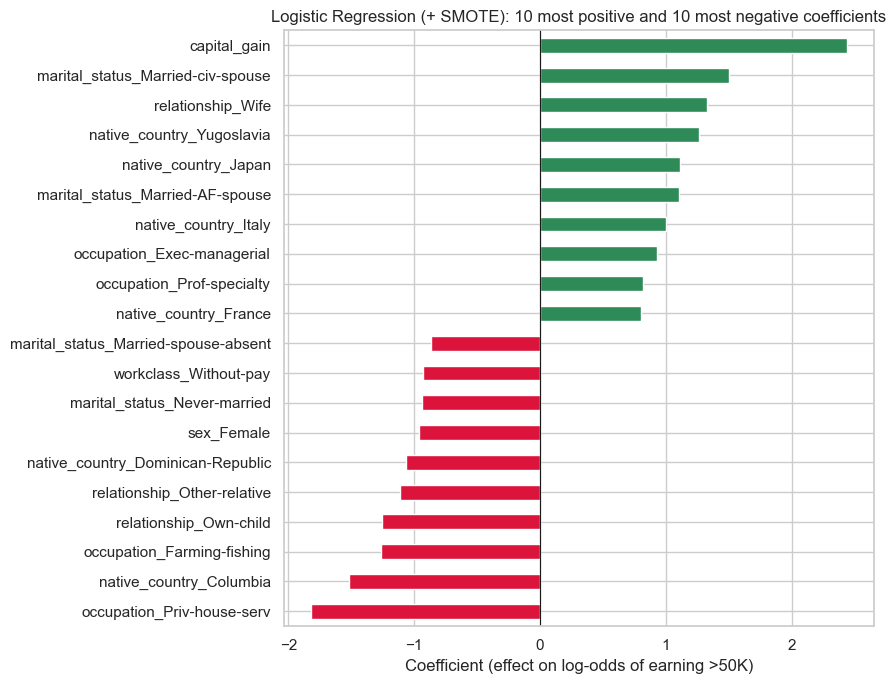

Odds ratios for the scaled numeric features (effect of +1 standard deviation):
capital_gain      11.49
education_num      2.08
hours_per_week     1.55
age                1.52
capital_loss       1.30
dtype: float64


In [17]:
lr_model = models["LR + SMOTE"]
feature_names = lr_model.named_steps["prep"].get_feature_names_out()
feature_names = [f.replace("num__", "").replace("cat__", "") for f in feature_names]
coefs = pd.Series(lr_model.named_steps["clf"].coef_[0], index=feature_names)

top = pd.concat([coefs.nlargest(10), coefs.nsmallest(10)]).sort_values()
plt.figure(figsize=(9, 7))
top.plot(kind="barh", color=["crimson" if c < 0 else "seagreen" for c in top])
plt.axvline(0, color="k", lw=0.8)
plt.title("Logistic Regression (+ SMOTE): 10 most positive and 10 most negative coefficients")
plt.xlabel("Coefficient (effect on log-odds of earning >50K)")
plt.tight_layout()
plt.show()

print("Odds ratios for the scaled numeric features (effect of +1 standard deviation):")
print(np.exp(coefs[num_cols]).round(2).sort_values(ascending=False))

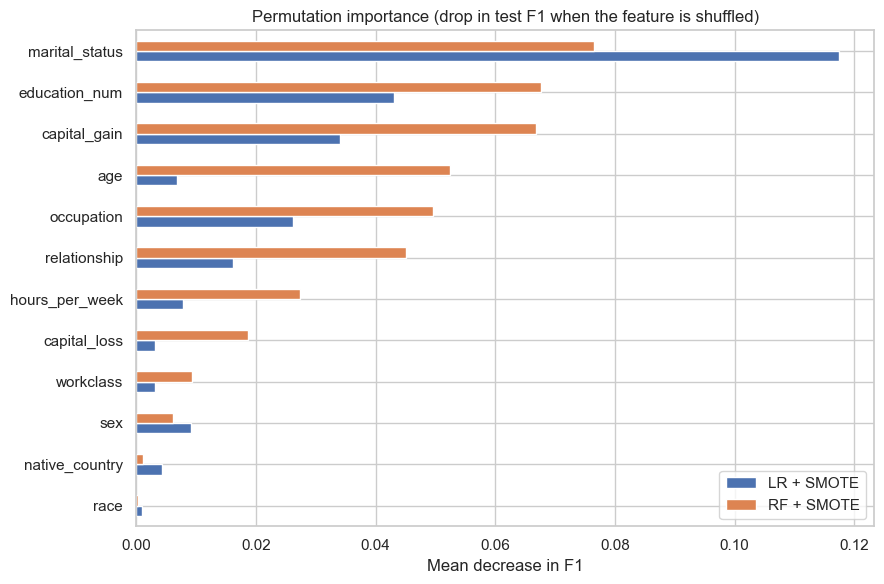

,LR + SMOTE,RF + SMOTE
marital_status,0.1174,0.0764
education_num,0.0431,0.0676
capital_gain,0.0340,0.0668
age,0.0068,0.0524
occupation,0.0262,0.0496
relationship,0.0162,0.0451
hours_per_week,0.0078,0.0273
capital_loss,0.0031,0.0187
workclass,0.0032,0.0092
sex,0.0092,0.0061


In [18]:
perm_results = {}
for name in ["LR + SMOTE", "RF + SMOTE"]:
    pi = permutation_importance(
        models[name], X_test, y_test, scoring="f1", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
    )
    perm_results[name] = pd.Series(pi.importances_mean, index=X_test.columns)

perm_df = pd.DataFrame(perm_results).sort_values("RF + SMOTE")
perm_df.plot(kind="barh", figsize=(9, 6))
plt.title("Permutation importance (drop in test F1 when the feature is shuffled)")
plt.xlabel("Mean decrease in F1")
plt.tight_layout()
plt.show()

perm_df.sort_values("RF + SMOTE", ascending=False).round(4)

#### Interpretation of feature importance

Both models largely agree on the most important features, which makes the conclusions more trustworthy:

* **Marital status / relationship** (especially being married, "Married-civ-spouse" or "Husband"/"Wife") is one of the strongest predictors. This partly reflects household structure and age rather than a direct causal effect: in 1994, married individuals (mostly men in this dataset) were more likely to be the main earner.
* **Capital gain** is a very strong signal. Most people report 0, but anyone with a large capital gain is very likely to earn >50K, since investment income is tied to wealth.
* **Education level (`education_num`)** has a clear positive effect: each additional level of education raises the odds of high income, in line with the exploratory plot and economic research.
* **Age** and **hours per week** are positive predictors, consistent with experience and working time being linked to income.
* **Occupation** matters: executive/managerial and professional-specialty jobs increase the odds, while service and manual jobs (e.g., "Priv-house-serv", "Other-service", "Handlers-cleaners") reduce them.
* **Race, native country and sex** contribute less once the other features are taken into account. Some of the sex effect is captured indirectly by the relationship feature ("Husband"/"Wife").

These results largely confirm our initial expectation (education, capital gains, age, hours and occupation), with the addition that **marital status / relationship** turned out to be among the strongest predictors. Note that these are associations in census data, not causal effects.

## 9. Improving the Results: Hyperparameter Tuning

So far all models used default or simple settings. To improve the results, we tune the **Random Forest + SMOTE** pipeline with `RandomizedSearchCV` (3-fold stratified CV on the training set, optimizing F1). We search over both the forest and SMOTE settings:

* `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`: limit how complex each tree is. Default forests grow very deep trees, which can overfit, especially on synthetic points.
* `smote__k_neighbors`: how many neighbors SMOTE interpolates between.
* `smote__sampling_strategy`: the target minority/majority ratio after resampling. A value below 1.0 (partial balancing) can reduce the false positives caused by full balancing.

*(This cell can take several minutes.)*

In [19]:
param_dist = {
    "clf__n_estimators": [200, 300, 400],
    "clf__max_depth": [10, 15, 20, None],
    "clf__min_samples_leaf": [1, 2, 4, 8],
    "clf__max_features": ["sqrt", 0.3],
    "smote__k_neighbors": [3, 5, 7],
    "smote__sampling_strategy": [0.5, 0.75, 1.0],
}

search = RandomizedSearchCV(
    smote_pipe(make_rf()),
    param_distributions=param_dist,
    n_iter=15,
    scoring="f1",
    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print(f"Best CV F1: {search.best_score_:.3f}")
print("Best parameters:")
for k, v in search.best_params_.items():
    print(f"  {k}: {v}")

Best CV F1: 0.709
Best parameters:
  smote__sampling_strategy: 0.75
  smote__k_neighbors: 7
  clf__n_estimators: 200
  clf__min_samples_leaf: 2
  clf__max_features: sqrt
  clf__max_depth: None


In [20]:
tuned_name = "RF + SMOTE (tuned)"
models[tuned_name] = search.best_estimator_
results[tuned_name], preds[tuned_name], probs[tuned_name] = evaluate(search.best_estimator_, X_test, y_test)

# Also try the same tuned forest with threshold tuning instead of SMOTE, for a fair comparison
best_rf_params = {k.replace("clf__", ""): v for k, v in search.best_params_.items() if k.startswith("clf__")}
tuned_thr_name = "RF tuned + threshold tuning"
models[tuned_thr_name] = threshold_tuned(plain_pipe(make_rf(**best_rf_params)))
models[tuned_thr_name].fit(X_train, y_train)
results[tuned_thr_name], preds[tuned_thr_name], probs[tuned_thr_name] = evaluate(models[tuned_thr_name], X_test, y_test)

results_df = pd.DataFrame(results).T
results_df.style.format("{:.3f}").highlight_max(axis=0, color="lightgreen")

,Accuracy,Balanced Acc.,Precision (>50K),Recall (>50K),F1 (>50K),ROC-AUC,PR-AUC
LR (baseline),0.847,0.766,0.734,0.606,0.664,0.900,0.766
LR + class weights,0.804,0.811,0.575,0.825,0.678,0.900,0.764
LR + threshold tuning,0.832,0.801,0.642,0.740,0.687,0.900,0.766
LR + SMOTE,0.805,0.812,0.575,0.826,0.678,0.899,0.763
RF (baseline),0.848,0.776,0.723,0.634,0.675,0.898,0.763
RF + threshold tuning,0.835,0.812,0.642,0.766,0.698,0.898,0.763
RF + SMOTE,0.840,0.787,0.677,0.682,0.680,0.892,0.735
RF + SMOTE (tuned),0.850,0.822,0.675,0.767,0.718,0.914,0.798
RF tuned + threshold tuning,0.856,0.819,0.697,0.746,0.721,0.917,0.809


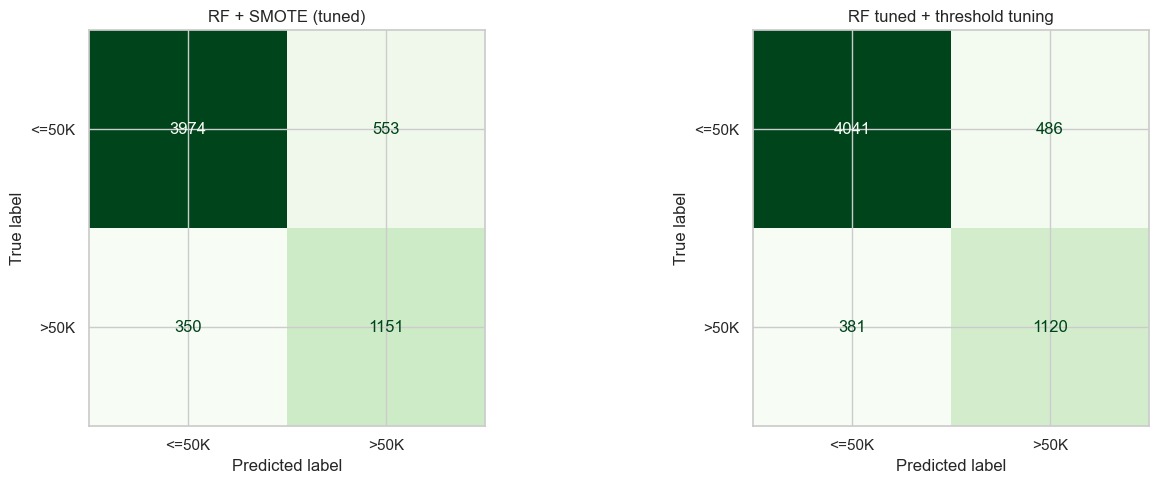

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, [tuned_name, tuned_thr_name]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds[name], display_labels=["<=50K", ">50K"], cmap="Greens", colorbar=False, ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 10. Final Model Selection and Conclusions

We select the best model by **F1 score on the >50K class** (our main metric), and use PR-AUC as a tie-breaker because it measures ranking quality independently of the threshold. The cell below picks the winner from the full results table and summarizes the key comparisons automatically.

In [22]:
final = results_df.sort_values(["F1 (>50K)", "PR-AUC"], ascending=False)
best_name = final.index[0]

display(final.style.format("{:.3f}").highlight_max(axis=0, color="lightgreen"))

base, sm = results_df.loc["LR (baseline)"], results_df.loc["LR + SMOTE"]
rf_base, rf_sm = results_df.loc["RF (baseline)"], results_df.loc["RF + SMOTE"]
print(f"Best model by F1 (>50K): {best_name}")
print(f"  F1 = {final.loc[best_name, 'F1 (>50K)']:.3f}, Precision = {final.loc[best_name, 'Precision (>50K)']:.3f}, "
      f"Recall = {final.loc[best_name, 'Recall (>50K)']:.3f}, PR-AUC = {final.loc[best_name, 'PR-AUC']:.3f}\n")
print("Effect of SMOTE:")
print(f"  Logistic Regression: recall {base['Recall (>50K)']:.3f} -> {sm['Recall (>50K)']:.3f}, "
      f"precision {base['Precision (>50K)']:.3f} -> {sm['Precision (>50K)']:.3f}, F1 {base['F1 (>50K)']:.3f} -> {sm['F1 (>50K)']:.3f}")
print(f"  Random Forest:       recall {rf_base['Recall (>50K)']:.3f} -> {rf_sm['Recall (>50K)']:.3f}, "
      f"precision {rf_base['Precision (>50K)']:.3f} -> {rf_sm['Precision (>50K)']:.3f}, F1 {rf_base['F1 (>50K)']:.3f} -> {rf_sm['F1 (>50K)']:.3f}")
print("\nSMOTE vs threshold tuning (F1):")
print(f"  LR: SMOTE {sm['F1 (>50K)']:.3f} vs threshold {results_df.loc['LR + threshold tuning', 'F1 (>50K)']:.3f}")
print(f"  RF: SMOTE {rf_sm['F1 (>50K)']:.3f} vs threshold {results_df.loc['RF + threshold tuning', 'F1 (>50K)']:.3f}")

,Accuracy,Balanced Acc.,Precision (>50K),Recall (>50K),F1 (>50K),ROC-AUC,PR-AUC
RF tuned + threshold tuning,0.856,0.819,0.697,0.746,0.721,0.917,0.809
RF + SMOTE (tuned),0.850,0.822,0.675,0.767,0.718,0.914,0.798
RF + threshold tuning,0.835,0.812,0.642,0.766,0.698,0.898,0.763
LR + threshold tuning,0.832,0.801,0.642,0.740,0.687,0.900,0.766
RF + SMOTE,0.840,0.787,0.677,0.682,0.680,0.892,0.735
LR + SMOTE,0.805,0.812,0.575,0.826,0.678,0.899,0.763
LR + class weights,0.804,0.811,0.575,0.825,0.678,0.900,0.764
RF (baseline),0.848,0.776,0.723,0.634,0.675,0.898,0.763
LR (baseline),0.847,0.766,0.734,0.606,0.664,0.900,0.766


Best model by F1 (>50K): RF tuned + threshold tuning
  F1 = 0.721, Precision = 0.697, Recall = 0.746, PR-AUC = 0.809

Effect of SMOTE:
  Logistic Regression: recall 0.606 -> 0.826, precision 0.734 -> 0.575, F1 0.664 -> 0.678
  Random Forest:       recall 0.634 -> 0.682, precision 0.723 -> 0.677, F1 0.675 -> 0.680

SMOTE vs threshold tuning (F1):
  LR: SMOTE 0.678 vs threshold 0.687
  RF: SMOTE 0.680 vs threshold 0.698


### Conclusions

*Note: confirm that the statements below match the printed summary above, and adjust the wording if your run differs.*

**Research question 1: Which features best predict income above $50K?**
Marital status / relationship, capital gain, education level, age, hours worked per week and occupation are the strongest predictors. Both Logistic Regression and Random Forest agree on this, and it matches our expectation with one addition: marital status (being married) turned out to be among the most important features.

**Research question 2: How effective is SMOTE compared with adjusting the decision threshold?**
SMOTE clearly reduces the misclassification of high earners: recall on the >50K class increases substantially for both models, at the cost of lower precision and slightly lower accuracy. However, simply moving the decision threshold (and, for Logistic Regression, using class weights) achieves a very similar precision/recall balance and F1 score. SMOTE also leaves ROC-AUC and PR-AUC almost unchanged. This shows that on this dataset SMOTE mainly works by shifting the decision boundary toward the minority class, not by teaching the model new patterns. Threshold tuning is cheaper and does not require synthetic data, so the two approaches should be seen as alternatives that reach a similar result.

**Best model.** The model printed above has the highest F1 on the >50K class, and it is our selected model for this prediction task. The Random Forest can capture non-linear effects and interactions, and tuning limits its overfitting; if the tuned forest wins, this is the reason. If a Logistic Regression variant wins or ties, it shows that a simple linear model is already enough for this data. If interpretability matters more than a small gain in F1, **Logistic Regression with SMOTE or with threshold tuning** is a strong, easily explained alternative.

**Limitations and possible extensions**
* The data comes from the 1994 census, so the $50K threshold and the relationships between features reflect that time period.
* Dropping rows with missing values removed about 7% of the data. These rows might not be missing at random.
* Standard SMOTE interpolates one-hot categorical columns, which creates non-integer category values. **SMOTE-NC** (designed for mixed numeric and categorical data) could be tested as an extension.
* Gradient boosting models (e.g., `HistGradientBoostingClassifier`) usually perform very well on this dataset and could be compared in future work.
* The features include sensitive attributes (sex, race). A real-world income model should be checked for fairness across these groups.

## 11. References

1. Becker, B. & Kohavi, R. (1996). *Adult* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20 (https://archive.ics.uci.edu/dataset/2/adult)
2. Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic Minority Over-sampling Technique. *Journal of Artificial Intelligence Research*, 16, 321–357. https://doi.org/10.1613/jair.953
3. Lemaître, G., Nogueira, F., & Aridas, C. K. (2017). Imbalanced-learn: A Python Toolbox to Tackle the Curse of Imbalanced Datasets in Machine Learning. *Journal of Machine Learning Research*, 18(17), 1–5. Documentation: https://imbalanced-learn.org/stable/over_sampling.html#smote-adasyn
4. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830. https://scikit-learn.org/
5. scikit-learn documentation: `TunedThresholdClassifierCV` (https://scikit-learn.org/stable/modules/classification_threshold.html), `permutation_importance` (https://scikit-learn.org/stable/modules/permutation_importance.html), `RandomForestClassifier` (https://scikit-learn.org/stable/modules/ensemble.html#forest).
6. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32. https://doi.org/10.1023/A:1010933404324
7. He, H. & Garcia, E. A. (2009). Learning from Imbalanced Data. *IEEE Transactions on Knowledge and Data Engineering*, 21(9), 1263–1284. https://doi.org/10.1109/TKDE.2008.239
8. van den Goorbergh, R., van Smeden, M., Timmerman, D., & Van Calster, B. (2022). The harm of class imbalance corrections for risk prediction models. *Journal of the American Medical Informatics Association*, 29(9), 1525–1534. https://doi.org/10.1093/jamia/ocac093
9. Elor, Y. & Averbuch-Elor, H. (2022). To SMOTE, or not to SMOTE? *arXiv:2201.08528*. https://arxiv.org/abs/2201.08528